# 02 三代模型训练与对比

| | 第一代 | 第二代 | 第三代 |
| --- | --- | --- | --- |
| 模型 | UNet（纯 PyTorch 手写） | SegFormer-B2（HF 实现） | SAM ViT-B（HF 实现） |
| 范式 | CNN 专用小模型，从零训练 | Transformer 通用分割，ImageNet 预训练 | 视觉大模型，零样本 + LoRA 微调 |
| 参数量 | 31.0M（全部训练） | 27.3M（全部微调） | 93.8M（冻结；LoRA 仅 98 万） |

三代使用**完全相同**的数据管道、损失（masked BCE+Dice）、评估口径（双掩膜内洪水类 IoU），保证可比。

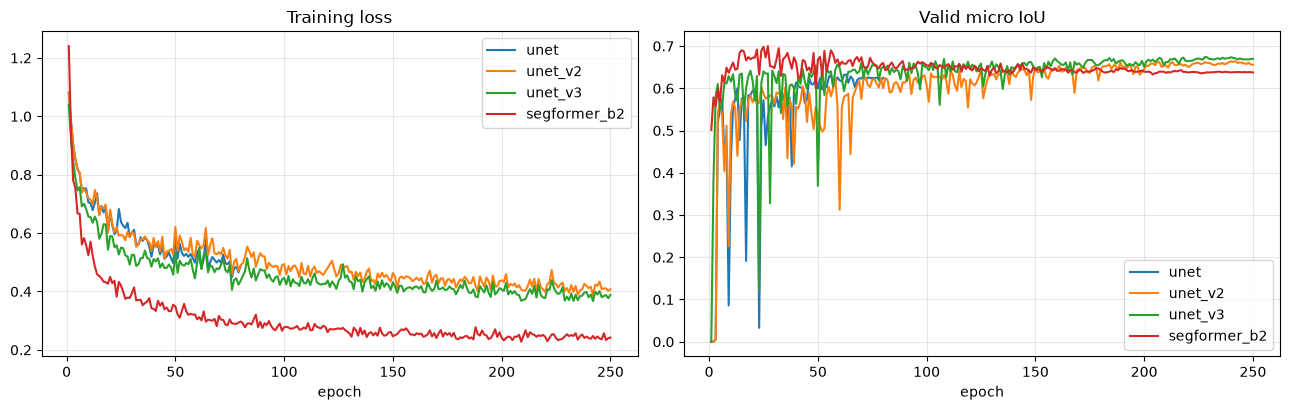

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

OUT = Path('../outputs')
hists = {t: pd.read_csv(OUT / f'{t}_history.csv')
         for t in ['unet', 'unet_v2', 'unet_v3', 'segformer_b2']}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for t, h in hists.items():
    axes[0].plot(h.epoch, h.loss, label=t)
    axes[1].plot(h.epoch, h.val_micro_iou, label=t)
axes[0].set_title('Training loss'); axes[0].set_xlabel('epoch')
axes[1].set_title('Valid micro IoU'); axes[1].set_xlabel('epoch')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## UNet 调优消融（问题诊断式调参）

| 版本 | 改动 | 结论 |
| --- | --- | --- |
| v1 | 80 epochs 基线 | 欠训练（终点仍在爬升） |
| v2 | 延长到 250 epochs | 收敛（终点斜率 +0.01/百轮），轮次假说证伪 |
| v3 | **修复 vh 通道被 vv 裁剪范围压扁**（分通道归一化） | SAR 两种极化差 5~10dB，共用范围丢失低回波段 |

v3 的修复来自对数据的再审视——这也是“预处理缺陷比模型结构更伤”的直接证据。

In [2]:
rows = []
for t, h in hists.items():
    if 'val_micro_iou' not in h:
        continue
    b = h.loc[h.val_macro_iou.idxmax()]
    rows.append({'版本': t, '最优轮次': int(b.epoch),
                 'valid microIoU': round(b.val_micro_iou, 4),
                 'valid macroIoU': round(b.val_macro_iou, 4),
                 'Precision': round(b.val_precision, 4), 'Recall': round(b.val_recall, 4)})
pd.DataFrame(rows)

,版本,最优轮次,valid microIoU,valid macroIoU,Precision,Recall
0,unet,63,0.6326,0.3697,0.7698,0.7802
1,unet_v2,228,0.6617,0.3979,0.8090,0.7842
2,unet_v3,170,0.6595,0.4105,0.7752,0.8153
3,segformer_b2,134,0.6588,0.4063,0.8035,0.7854


## 定性对比：同一张图上的三代表现

从 test 集选取 UNet 表现**最差 / 中位 / 最好**的三张图（按逐 chip IoU 排序），对比真值、UNet、SegFormer 的分割结果。

/home/ctgu53/work/cv-course-design/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 364/364 [00:00<00:00, 19820.93it/s]


[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias  

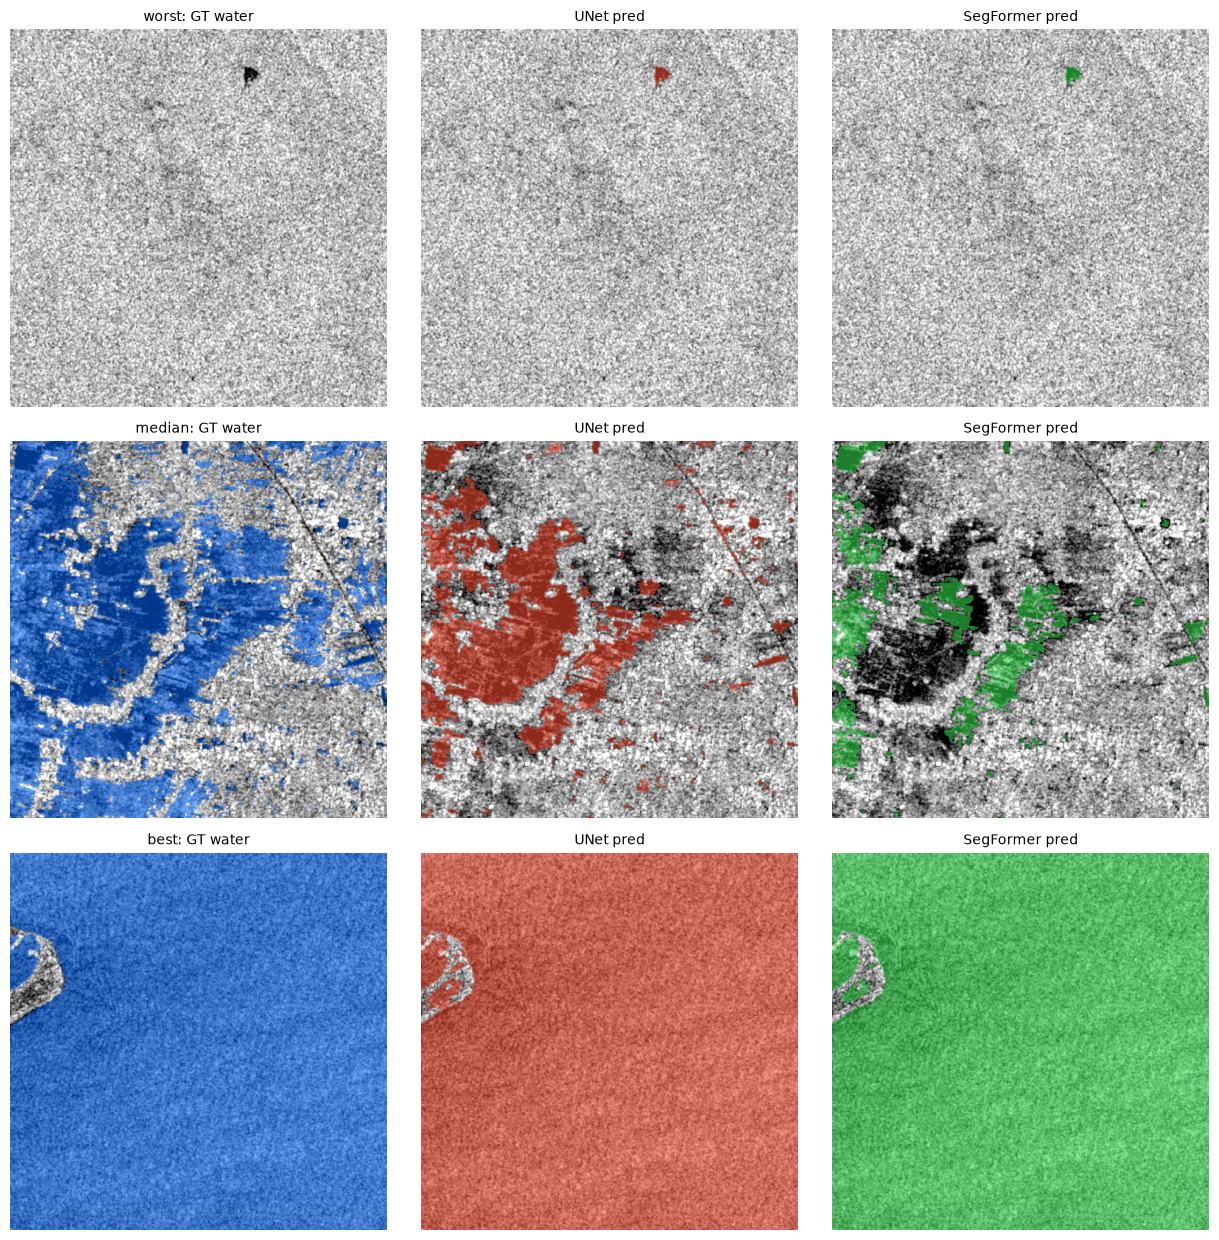

In [3]:
import numpy as np
import torch
from src.dataset import Sen1FloodsDataset
from src.models import FACTORIES

device = 'cuda'

def load_model(tag, key):
    ck = torch.load(OUT / 'checkpoints' / f'{tag}_best.pth', map_location=device, weights_only=True)
    m = FACTORIES[key]().to(device).eval()
    m.load_state_dict(ck['model'])
    return m

unet = load_model('unet_v3', 'unet')
segf = load_model('segformer_b2', 'segformer')
ds = Sen1FloodsDataset('test', augment=False)

per = pd.read_csv(OUT / 'unet_v3_eval_per_chip.csv')
tp = per[per.split == 'test'].sort_values('iou').reset_index(drop=True)
names = [tp.chip[0], tp.chip[len(tp) // 2], tp.chip.iloc[-1]]
idxs = [[j for j, s in enumerate(ds.samples) if s[0] == n][0] for n in names]

fig, axes = plt.subplots(3, 3, figsize=(12.5, 12.5))
for r, i in enumerate(idxs):
    img, water, valid, name = ds[i]
    v = valid.numpy()
    x = img.unsqueeze(0).to(device)
    with torch.no_grad():
        pu = ((torch.sigmoid(unet(x))[0, 0].cpu().numpy() > 0.5) * v)
        ps = ((torch.sigmoid(segf(x))[0, 0].cpu().numpy() > 0.5) * v)
    gt = (water[0].numpy() > 0.5) * v
    tag = ['worst', 'median', 'best'][r]
    axes[r][0].imshow(img[0], cmap='gray')
    ov = np.zeros((*v.shape, 4)); ov[gt > 0] = [0, 0.4, 1, 0.55]
    axes[r][0].imshow(ov); axes[r][0].set_title(f'{tag}: GT water', fontsize=10)
    axes[r][1].imshow(img[0], cmap='gray')
    ov = np.zeros((*v.shape, 4)); ov[pu > 0] = [1, 0.3, 0.2, 0.55]
    axes[r][1].imshow(ov); axes[r][1].set_title(f'UNet pred', fontsize=10)
    axes[r][2].imshow(img[0], cmap='gray')
    ov = np.zeros((*v.shape, 4)); ov[ps > 0] = [0.2, 0.9, 0.3, 0.55]
    axes[r][2].imshow(ov); axes[r][2].set_title(f'SegFormer pred', fontsize=10)
    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout(); plt.show()

## 正式评估汇总（三代四行）

SAM 两行见 `04_sam_analysis.ipynb` 的同协议评估；此处为全监督两代。

In [4]:
rows = []
name_map = {'unet_v3': 'UNet 手写 (31M)', 'segformer_b2': 'SegFormer-B2 (27M)'}
for tag, nice in name_map.items():
    e = pd.read_csv(OUT / f'{tag}_eval.csv')
    for _, r in e.iterrows():
        rows.append({'模型': nice, 'split': r['split'], 'microIoU': round(r.micro_iou, 4),
                     'Precision': round(r.precision, 4), 'Recall': round(r.recall, 4),
                     'Dice': round(r.dice, 4)})
pd.DataFrame(rows)

,模型,split,microIoU,Precision,Recall,Dice
0,UNet 手写 (31M),valid,0.6595,0.7752,0.8153,0.7948
1,UNet 手写 (31M),test,0.6644,0.7886,0.8083,0.7984
2,UNet 手写 (31M),bolivia,0.6963,0.8003,0.8426,0.8209
3,SegFormer-B2 (27M),valid,0.6588,0.8035,0.7854,0.7943
4,SegFormer-B2 (27M),test,0.6807,0.8399,0.7823,0.8101
5,SegFormer-B2 (27M),bolivia,0.5708,0.8214,0.6517,0.7268


## 阶段结论

1. **分布内（test）**：SegFormer 预训练带来 +1.7 IoU 增益，Precision 提升最明显（0.84）——预训练特征对边界精细度有帮助
2. **分布外（Bolivia）**：形势反转——SegFormer 塌方 12.5 个点（Recall 0.65），UNet 反而最高（0.696）。自然图像预训练特征迁到陌生洪水分布上失灵；CNN 的归纳偏置（局部性、平移等变性）更皮实
3. **工程启示**：水利业务部署要按“会不会遇到没见过的事件”选模型——常态化监测可用更强的预训练模型，应急/极端事件场景专用小模型更可靠